In [2]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.1-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.84.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-win_amd64.whl.metadata (8.8 kB)
  Using cached whe


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [4]:
df = pd.read_csv("heart.csv")

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X = pd.get_dummies(X, drop_first=True, dtype=int)
X = X.fillna(X.median())

print("Dataset Shape:", X.shape)

Dataset Shape: (918, 15)


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (642, 15)
Validation data: (138, 15)
Testing data: (138, 15)


In [6]:
model = Sequential([
    Dense(32, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\Krupali\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Training completed!")

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7118 - loss: 0.5502 - val_accuracy: 0.8478 - val_loss: 0.4591
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8349 - loss: 0.4545 - val_accuracy: 0.9058 - val_loss: 0.3808
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8489 - loss: 0.3970 - val_accuracy: 0.8913 - val_loss: 0.3367
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8551 - loss: 0.3620 - val_accuracy: 0.8913 - val_loss: 0.3153
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8614 - loss: 0.3435 - val_accuracy: 0.8913 - val_loss: 0.3088
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8676 - loss: 0.3316 - val_accuracy: 0.8913 - val_loss: 0.3019
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8707 - loss: 0.3235 - val_accuracy: 0.8841 - val_loss: 0.3093
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8707 - loss: 0.3175 - val_accuracy: 0.8841 - val_loss

In [8]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

for i in range(len(train_loss)):
    print(
        "Epoch:", i + 1,
        "Training Loss:", round(train_loss[i], 4),
        "Validation Loss:", round(val_loss[i], 4)
    )

Epoch: 1 Training Loss: 0.5502 Validation Loss: 0.4591
Epoch: 2 Training Loss: 0.4545 Validation Loss: 0.3808
Epoch: 3 Training Loss: 0.397 Validation Loss: 0.3367
Epoch: 4 Training Loss: 0.362 Validation Loss: 0.3153
Epoch: 5 Training Loss: 0.3435 Validation Loss: 0.3088
Epoch: 6 Training Loss: 0.3316 Validation Loss: 0.3019
Epoch: 7 Training Loss: 0.3235 Validation Loss: 0.3093
Epoch: 8 Training Loss: 0.3175 Validation Loss: 0.303
Epoch: 9 Training Loss: 0.3117 Validation Loss: 0.304
Epoch: 10 Training Loss: 0.3073 Validation Loss: 0.2989
Epoch: 11 Training Loss: 0.3018 Validation Loss: 0.2976
Epoch: 12 Training Loss: 0.2973 Validation Loss: 0.2968
Epoch: 13 Training Loss: 0.2933 Validation Loss: 0.2979
Epoch: 14 Training Loss: 0.2897 Validation Loss: 0.3003
Epoch: 15 Training Loss: 0.286 Validation Loss: 0.2962
Epoch: 16 Training Loss: 0.2832 Validation Loss: 0.3005
Epoch: 17 Training Loss: 0.28 Validation Loss: 0.2944
Epoch: 18 Training Loss: 0.2763 Validation Loss: 0.2971
Epoch: 1

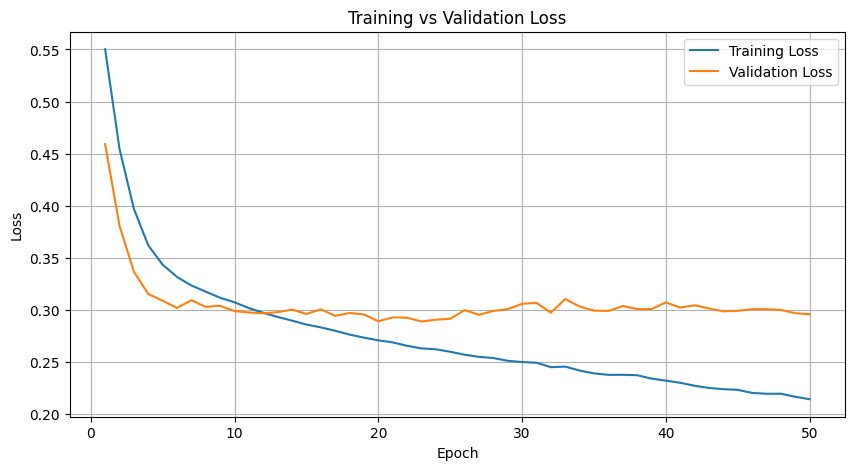

In [9]:
epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [11]:
min_val_loss = min(val_loss)
best_epoch = val_loss.index(min_val_loss) + 1

print("Lowest Validation Loss:", round(min_val_loss, 4))
print("Best Epoch:", best_epoch)

if val_loss[-1] > val_loss[best_epoch - 1]:
    print("Validation loss best in.")
    print(" check Possible overfitting  .")
else:
    print(" Validation loss best epoch in .")
    print(" Learning trend in more  evaluate that")

Lowest Validation Loss: 0.289
Best Epoch: 23
Validation loss best in.
 check Possible overfitting  .
